# NWSP demo

This notebook shows how to use Neural Wasserstein Splines (NWSP) and NWSP-N:

1. the datasets;
2. NWSP with a held-out snapshot, scored with exact W1 and W2 and the MMD;
3. NWSP-N, with learned potentials;
4. every snapshot of the three toy datasets fitted;
5. Petal with the paper's settings, one snapshot held out;
6. sampling at and between the observed times, particle paths, saving and loading, with a model fitted to every snapshot of the Circular Gaussian benchmark.

Sections 2-4 use small settings and take about 2 minutes on one CPU thread. Sections 5 and 6 make two fits with the paper's settings: about 12 minutes on an A100 GPU, or about 15 minutes on one CPU thread. A GPU is used for them when there is one; without one, six CPU threads (`torch.set_num_threads(6)` in the next cell) are as fast as the A100 or faster, but the scores can then differ from the README's one-thread values.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import torch

from data_gen import DATASETS, TOY_DATASETS, get_dataset, split_dataset
from nwsp import NWSPConfig, NWSPNConfig, NWSPNTrainer, NWSPTrainer, load_model
from utils import evaluate_split, plot_figure, plot_snapshots

device = 'cuda' if torch.cuda.is_available() else 'cpu'   # device of the fits with the paper's settings (5 and 6)
torch.set_num_threads(1)                    # one CPU thread, as for the README's reference scores
logging.basicConfig(level=logging.WARNING)  # logging.INFO shows the training progress
plt.rcParams['figure.dpi'] = 80
print('device:', device)

device: cuda


## 1. Data

`get_dataset(name)` returns the snapshots of a dataset: `times` (T,), `frames` (T arrays of shape (n_t, d)) and the weights of the observed points in the scores. `DATASETS` lists the 13 names: the three toy datasets used below, four synthetic benchmarks and six single-cell or simulated benchmarks (files in `Data/`).

('circular', 'converging', 'expanding', 'diverging_gaussians', 'diamonds', 'converging_gaussian', 'circular_gaussian', 'dyngen_tree', 'dyngen_cycle', 'eb_phate', 'bsbm_mouse', 'bsbm_veres', 'citeseq')
circular: T = 5, d = 2, sizes = [256, 256, 256, 256, 256], times = [0.   0.25 0.5  0.75 1.  ]
converging: T = 5, d = 2, sizes = [256, 256, 256, 256, 256], times = [0.   0.25 0.5  0.75 1.  ]
expanding: T = 5, d = 2, sizes = [256, 256, 256, 256, 256], times = [0.   0.25 0.5  0.75 1.  ]


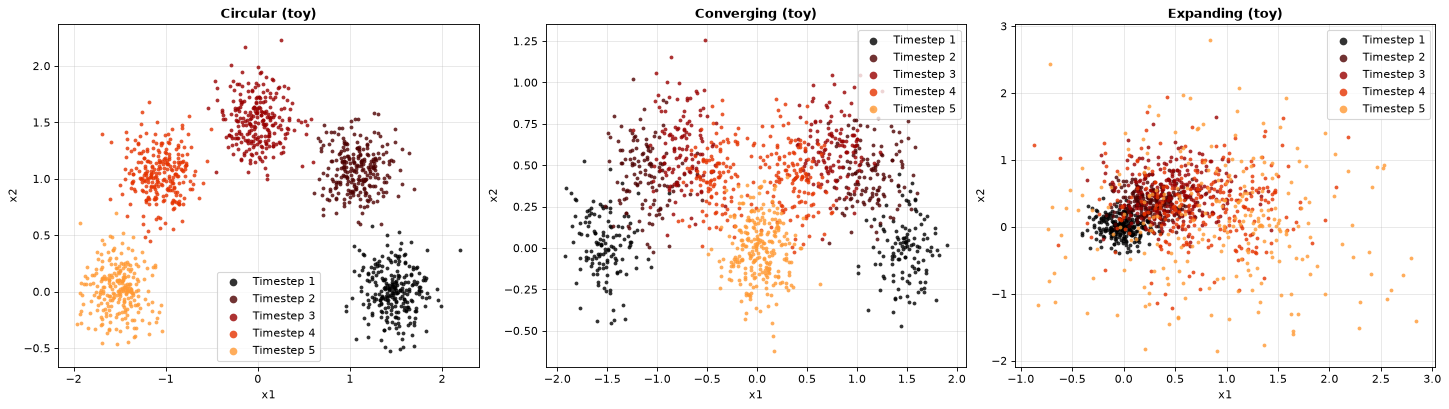

In [2]:
print(DATASETS)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), layout='constrained')
for ax, name in zip(axes, TOY_DATASETS):
    data = get_dataset(name)
    print(f'{name}: T = {data.T}, d = {data.d}, sizes = {data.sizes}, times = {data.times}')
    plot_figure(None, None, data.frames, ax=ax, title=data.label)
plt.show()

## 2. NWSP with a held-out snapshot

Withhold the middle snapshot of the `circular` toy data, fit NWSP to the other four and score the prediction at the withheld time against the withheld snapshot. `NWSPConfig.quickstart()` uses small networks and batches and 200 steps; `NWSPConfig()` gives the paper's settings. These small fits run faster on one CPU thread than on a GPU, so sections 2-4 keep the default `device='cpu'`.

NWSP held out 2: W1 0.1446  W2 0.1579  MMD 0.0270
trained in 9.2 s


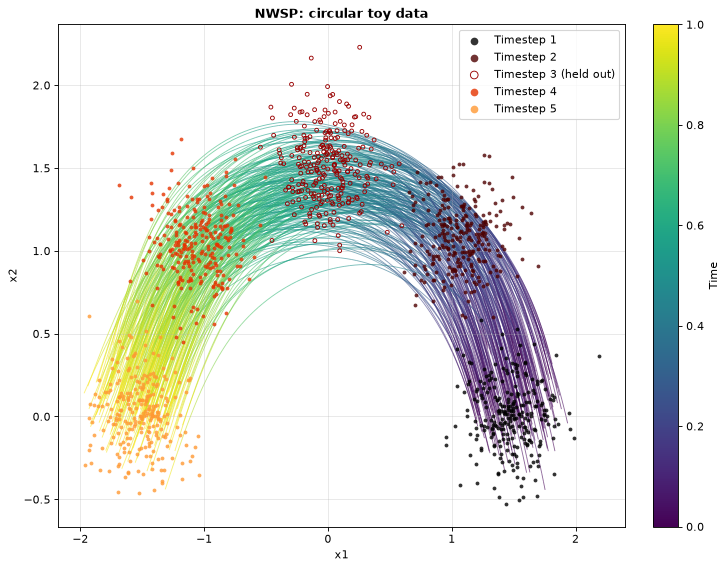

In [3]:
data = get_dataset('circular')
split = split_dataset(data, held_out=[2])

nwsp = NWSPTrainer(split.train_times, split.train_frames, NWSPConfig.quickstart())
nwsp.fit()
res_nwsp = evaluate_split(nwsp, split)
s = res_nwsp['held_out'][2]
print(f"NWSP held out 2: W1 {s['W1']:.4f}  W2 {s['W2']:.4f}  MMD {s['MMD']:.4f}")
print(f'trained in {nwsp.train_seconds:.1f} s')

t = np.linspace(0, 1, 101)
paths = nwsp.sample_paths(t, n=200, seed=0)
plot_figure(paths, t, split.frames, held_out=[2], title='NWSP: circular toy data', figsize=(9, 7))
plt.show()

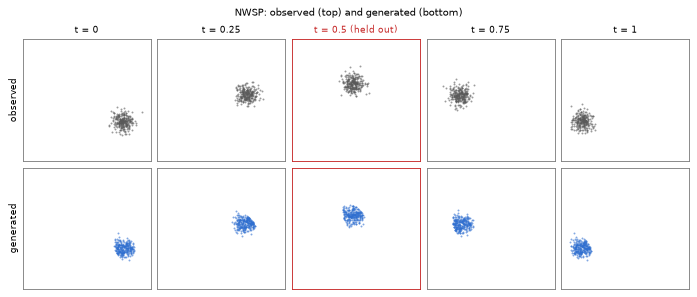

In [4]:
generated = [res_nwsp['samples'].get(i) for i in range(data.T)]
plot_snapshots(split.frames, generated, data.times, held_out=[2], title='NWSP: observed (top) and generated (bottom)')
plt.show()

## 3. NWSP-N

NWSP-N appends learned potentials to the fixed dictionary of the penalty; with the generator fixed, potential updates train them to capture as much of the population velocity as possible, in alternation with the generator updates (16 learned potentials in the paper's design, 8 in the quickstart settings).

In [5]:
nwspn = NWSPNTrainer(split.train_times, split.train_frames, NWSPNConfig.quickstart())
nwspn.fit()
res_nwspn = evaluate_split(nwspn, split)

for name, res in (('NWSP', res_nwsp), ('NWSP-N', res_nwspn)):
    s = res['held_out'][2]
    fit_w1 = np.mean(list(res['retained_w1'].values()))
    print(f"{name:7s} held out 2: W1 {s['W1']:.4f}  W2 {s['W2']:.4f}  MMD {s['MMD']:.4f};  "
          f"retained-fit W1 {fit_w1:.4f}")

NWSP    held out 2: W1 0.1446  W2 0.1579  MMD 0.0270;  retained-fit W1 0.0848
NWSP-N  held out 2: W1 0.1445  W2 0.1573  MMD 0.0273;  retained-fit W1 0.0847


## 4. All toy datasets, every snapshot fitted (NWSP-N)

`split_dataset(data)` without held-out snapshots fits every snapshot; the W1 distance between the generated and the observed snapshots measures the fit.

circular: retained-fit W1 0.0901  (trained in 13 s)


converging: retained-fit W1 0.1229  (trained in 66 s)


expanding: retained-fit W1 0.1076  (trained in 13 s)


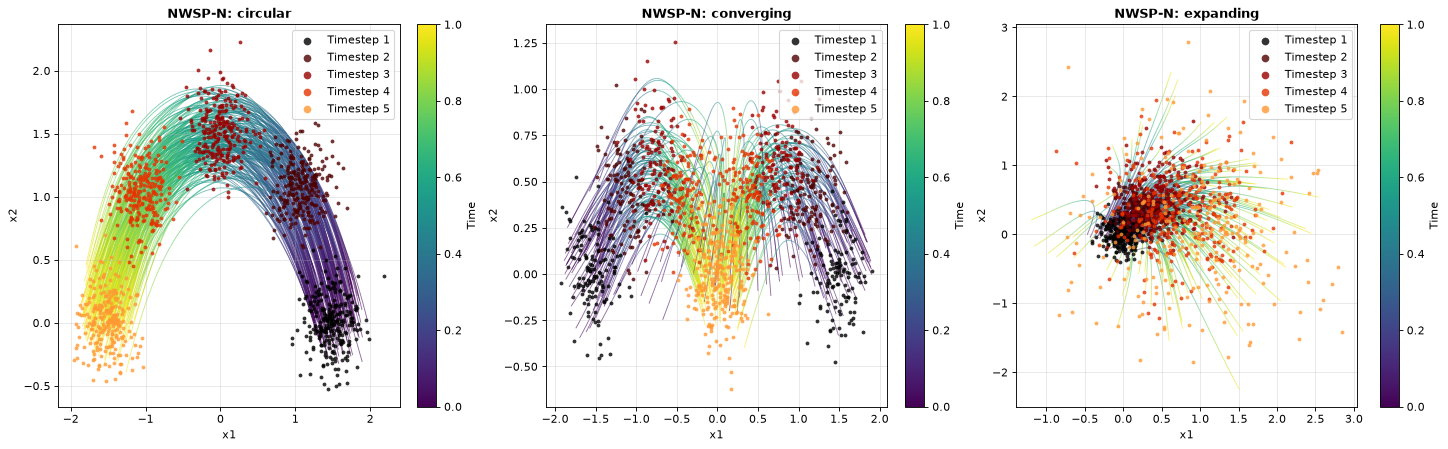

In [6]:
t = np.linspace(0, 1, 101)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), layout='constrained')
for ax, name in zip(axes, TOY_DATASETS):
    data = get_dataset(name)
    split_all = split_dataset(data)
    if name == 'converging':
        config = NWSPNConfig.quickstart(steps=1000, warmup_steps=200)   # the two merging blobs need more steps
    else:
        config = NWSPNConfig.quickstart()
    trainer = NWSPNTrainer(split_all.train_times, split_all.train_frames, config).fit()
    res = evaluate_split(trainer, split_all)
    fit_w1 = np.mean(list(res['retained_w1'].values()))
    print(f'{name}: retained-fit W1 {fit_w1:.4f}  (trained in {trainer.train_seconds:.0f} s)')
    plot_figure(trainer.sample_paths(t, n=200, seed=0), t, split_all.frames, ax=ax, title=f'NWSP-N: {name}')
plt.show()

## 5. Petal with the paper's settings

`NWSPConfig()` gives the paper's settings (3000 steps); `device=device` runs the fit on the GPU when there is one. Snapshot 2 of Petal is withheld and scored. The fit takes about 4 minutes on an A100, about 6 minutes on one CPU thread, or about 4 minutes on six CPU threads. `NWSPNTrainer` with `NWSPNConfig(device=device)` fits NWSP-N with the paper's settings in the same way, in about 5, 8.5 and 6 minutes.

On one CPU thread the fit gives the README's reference score, held-out W1 0.1128, the same as `python run_nwsp.py --dataset diamonds --held_out 2` (NWSP-N: 0.1166, with `--method NWSP-N`). A GPU gives other scores: CUDA draws other random numbers and uses other kernels, so its fit is another random draw of the same method. On the A100 used for the output below the held-out W1 is 0.089; for comparison, NWSP on one CPU thread gives 0.113, 0.102 and 0.101 with the seeds 0, 1 and 2.

NWSP held out 2: W1 0.0887  W2 0.1051  MMD 0.0124  (README, one CPU thread: W1 0.1128)
trained in 227 s on cuda


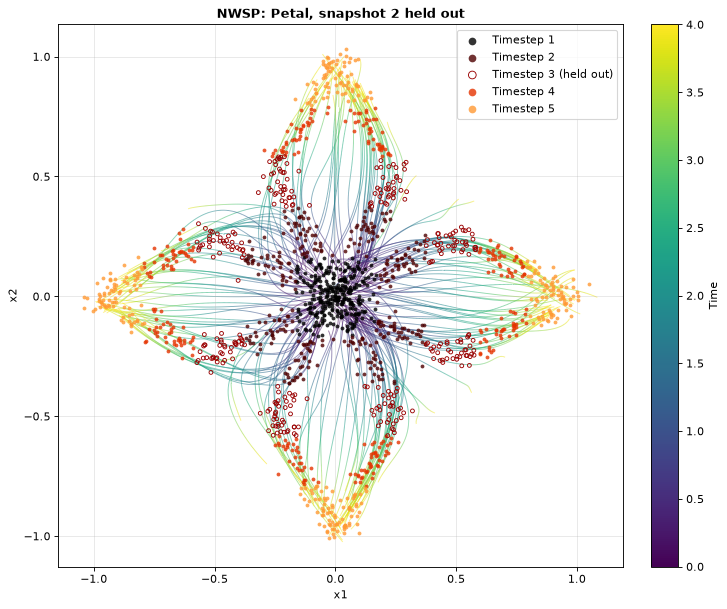

In [7]:
petal = get_dataset('diamonds')
split_p = split_dataset(petal, held_out=[2])

petal_nwsp = NWSPTrainer(split_p.train_times, split_p.train_frames, NWSPConfig(device=device)).fit()
s = evaluate_split(petal_nwsp, split_p, retained=False)['held_out'][2]
print(f"NWSP held out 2: W1 {s['W1']:.4f}  W2 {s['W2']:.4f}  MMD {s['MMD']:.4f}  (README, one CPU thread: W1 0.1128)")
print(f'trained in {petal_nwsp.train_seconds:.0f} s on {device}')

t = np.linspace(0, 4, 201)
plot_figure(petal_nwsp.sample_paths(t, n=300, seed=0), t, split_p.frames, held_out=[2],
            title='NWSP: Petal, snapshot 2 held out', figsize=(9, 7.5))
plt.show()

## 6. Sampling at any time, paths, saving and loading

A fitted model samples the population at any time of its fitted range with one network evaluation. This section uses the Circular Gaussian benchmark: ten snapshots, at t = 0, 1, ..., 9, of a Gaussian cloud of 100 points whose centre moves around a circle. Every snapshot is a single cloud, so it is easy to see where the samples between two snapshots lie. NWSP is fitted to every snapshot (`split_dataset(circ)` withholds none) with the paper's settings and the paper's penalty weight for this dataset, `lambda_acc=1e-8`, which takes about 8 minutes on an A100, or about 9 minutes on one CPU thread.

In [8]:
circ = get_dataset('circular_gaussian')
circ_all = split_dataset(circ)                         # every snapshot fitted
model = NWSPTrainer(circ_all.train_times, circ_all.train_frames, NWSPConfig(device=device, lambda_acc=1e-8)).fit()
fit_w1 = evaluate_split(model, circ_all)['retained_w1']
print(f'trained in {model.train_seconds:.0f} s; W1 at the observed snapshots:',
      ', '.join(f'{w:.2f}' for w in fit_w1.values()))

trained in 482 s; W1 at the observed snapshots: 0.26, 0.24, 0.24, 0.23, 0.22, 0.22, 0.25, 0.26, 0.24, 0.24


`model.sample(t, n)` draws n samples at any time t. Below, the generated samples (blue) at the observed times t = 0, 1, ..., 9 (left) and halfway between them, t = 0.5, 1.5, ..., 8.5 (right), are drawn over the observed snapshots (grey); the numbers are the times of the blue clouds. Each halfway cloud lies between its two neighbouring snapshots, on the circle along which the cloud moves.

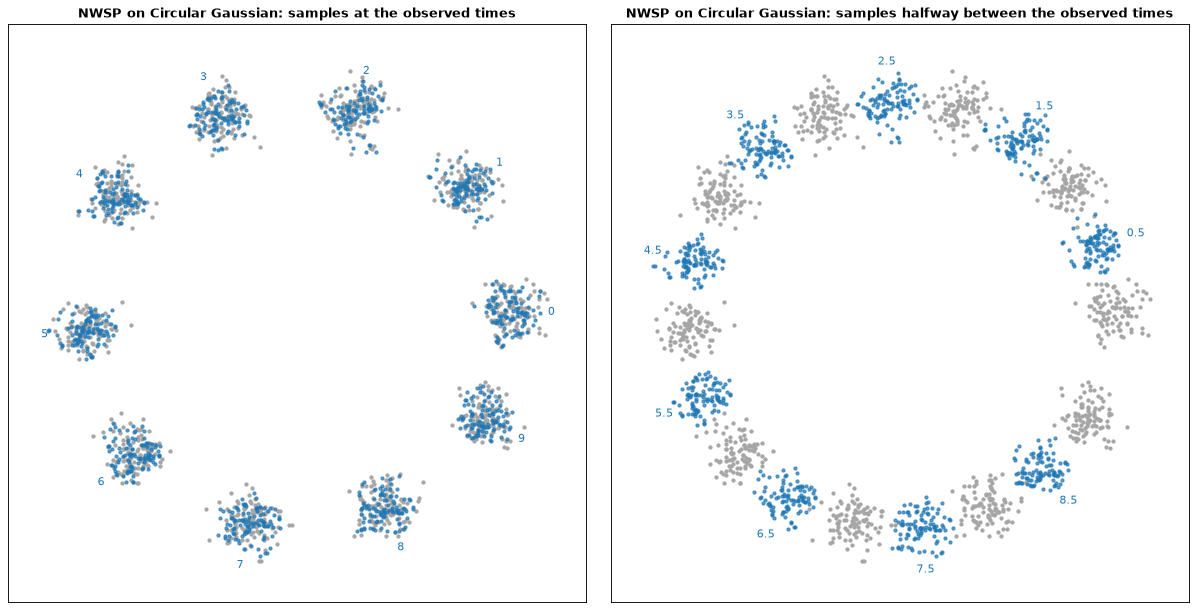

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), layout='constrained')
for ax, times, title in ((axes[0], circ.times, 'at the observed times'),
                         (axes[1], circ.times[:-1] + 0.5, 'halfway between the observed times')):
    for X in circ.frames:
        ax.scatter(*X.T, s=8, color='0.65')                # observed snapshots
    for t in times:
        x = model.sample(t, n=100, seed=0)                 # (100, 2) samples at time t
        ax.scatter(*x.T, s=8, color='tab:blue', alpha=0.7)
        ax.annotate(f'{t:g}', 1.2 * x.mean(0), ha='center', va='center', color='tab:blue')
    ax.set(xlim=(-13.5, 13.5), ylim=(-13.5, 13.5), aspect='equal', xticks=[], yticks=[])
    ax.set_title(f'NWSP on Circular Gaussian: samples {title}', fontweight='bold')
plt.show()

`sample_paths` draws particle paths: the same latent draws at every time, so `paths[:, i]` follows one particle through the fitted time range.

(451, 300, 2)


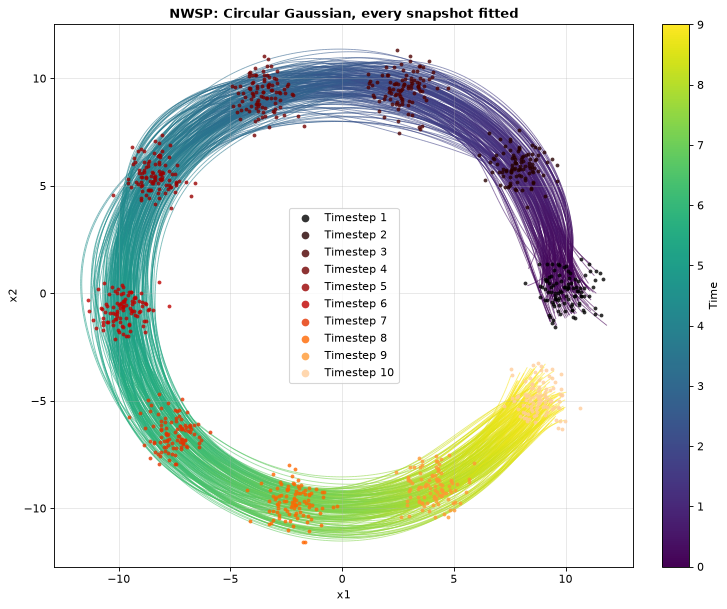

In [10]:
t = np.linspace(0, 9, 451)
paths = model.sample_paths(t, n=300, seed=0)          # (451, 300, 2): 300 particles at 451 times
print(paths.shape)
plot_figure(paths, t, circ_all.frames, title='NWSP: Circular Gaussian, every snapshot fitted', figsize=(9, 7.5))
plt.show()

`save` writes a weights-only checkpoint, and `load_model` restores the model for sampling (on the training device when it is available).

In [11]:
x = model.sample(4.5, n=1000, seed=0)                  # (1000, 2) samples at t = 4.5
model.save('results/circular_gaussian_nwsp.pt')
loaded = load_model('results/circular_gaussian_nwsp.pt')
print(x.shape, 'samples of the loaded model equal:', np.array_equal(loaded.sample(4.5, n=1000, seed=0), x))

(1000, 2) samples of the loaded model equal: True
